In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
df = pd.read_csv("dataset_preprocessed.csv")
text_column = "processed_text"

df = df.dropna(subset=[text_column])

# Gunakan sample untuk eksperimen awal
sample = df[text_column].head(1000).astype(str).tolist()
print(f"Jumlah dokumen sample: {len(sample)}")

Jumlah dokumen sample: 1000


In [3]:
# Inisialisasi CountVectorizer
vectorizer_bow = CountVectorizer(max_features=5000)

# Fit dan transform
bow_matrix = vectorizer_bow.fit_transform(sample)

print("Shape matriks BoW:", bow_matrix.shape)
print("Jumlah vocabulary :", len(vectorizer_bow.vocabulary_))

# Melihat vocabulary:
vocab = vectorizer_bow.get_feature_names_out()
print("Contoh vocabulary:", vocab[:20])

# Melihat representasi satu dokumen:
# Dokumen pertama dalam bentuk dense array
doc_vector = bow_matrix[0].toarray()[0]

# Tampilkan kata yang memiliki nilai > 0
nonzero_indices = np.where(doc_vector > 0)[0]
print("\nDokumen 1:")
print(sample[0])
print("\nRepresentasi BoW (kata dengan frekuensi > 0):")
for idx in nonzero_indices:
    print(f"  {vocab[idx]:<20} : {int(doc_vector[idx])}")

Shape matriks BoW: (1000, 2207)
Jumlah vocabulary : 2207
Contoh vocabulary: ['abai' 'abdul' 'ac' 'acl' 'acu' 'ada' 'adam' 'adaptasi' 'adat' 'adeyemi'
 'adik' 'adil' 'adriansyah' 'adu' 'afa' 'afc' 'affleck' 'agama' 'agenda'
 'agung']

Dokumen 1:
deret aktor peran spiderman

Representasi BoW (kata dengan frekuensi > 0):
  aktor                : 1
  deret                : 1
  peran                : 1
  spiderman            : 1


In [4]:
# Sparsity
total_elements = bow_matrix.shape[0] * bow_matrix.shape[1]
nonzero_elements = bow_matrix.nnz
sparsity = 1 - (nonzero_elements / total_elements)

print(f"Total elemen       : {total_elements:,}")
print(f"Elemen non-zero    : {nonzero_elements:,}")
print(f"Sparsity           : {sparsity:.4%}")

Total elemen       : 2,207,000
Elemen non-zero    : 8,607
Sparsity           : 99.6100%


In [5]:
# Inisialisasi TfidfVectorizer
vectorizer_tfidf = TfidfVectorizer(max_features=5000)

# Fit dan transform
tfidf_matrix = vectorizer_tfidf.fit_transform(sample)

print("Shape matriks TF-IDF:", tfidf_matrix.shape)

# Melihat kata dengan skor TF-IDF tertinggi pada dokumen tertentu:
def top_tfidf_words(doc_index, tfidf_mat, feature_names, top_n=10):
    doc_vector = tfidf_mat[doc_index].toarray()[0]
    top_indices = doc_vector.argsort()[::-1][:top_n]
    return [(feature_names[i], doc_vector[i]) for i in top_indices if doc_vector[i] > 0]

feature_names = vectorizer_tfidf.get_feature_names_out()

print("Top 10 kata TF-IDF Dokumen 0:")
print(sample[0][:150])
print()
for word, score in top_tfidf_words(0, tfidf_matrix, feature_names):
    print(f"  {word:<20} : {score:.4f}")

Shape matriks TF-IDF: (1000, 2207)
Top 10 kata TF-IDF Dokumen 0:
deret aktor peran spiderman

  spiderman            : 0.5704
  deret                : 0.5156
  peran                : 0.4979
  aktor                : 0.4012


In [6]:
# Hitung similarity antar dokumen:
# Ambil 5 dokumen pertama
subset = tfidf_matrix[:5]

# Hitung cosine similarity
sim_matrix = cosine_similarity(subset)

print("Cosine Similarity Matrix (5 dokumen):")
print(np.round(sim_matrix, 3))

Cosine Similarity Matrix (5 dokumen):
[[1.    0.128 0.111 0.111 0.12 ]
 [0.128 1.    0.254 0.334 0.193]
 [0.111 0.254 1.    0.221 0.168]
 [0.111 0.334 0.221 1.    0.168]
 [0.12  0.193 0.168 0.168 1.   ]]


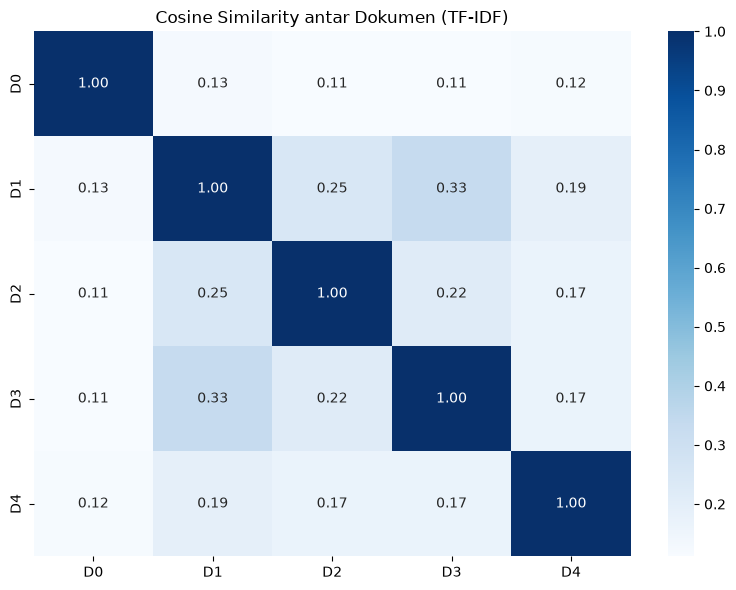

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    sim_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=[f"D{i}" for i in range(5)],
    yticklabels=[f"D{i}" for i in range(5)]
)
plt.title("Cosine Similarity antar Dokumen (TF-IDF)")
plt.tight_layout()
plt.show()

In [8]:
# Diberikan query, cari dokumen paling mirip:
def search_documents(query, vectorizer, tfidf_mat, docs, top_n=5):
    query_vec = vectorizer.transform([query])
    similarities = cosine_similarity(query_vec, tfidf_mat)[0]
    top_indices = similarities.argsort()[::-1][:top_n]
    results = []
    for idx in top_indices:
        results.append({
            "index": idx,
            "similarity": similarities[idx],
            "text": docs[idx][:100]
        })
    return results

# Contoh
query = "produk bagus kualitas"
results = search_documents(query, vectorizer_tfidf, tfidf_matrix, sample)

print(f"Query: '{query}'")
print("=" * 60)
for i, res in enumerate(results, 1):
    print(f"{i}. [Score: {res['similarity']:.4f}]")
    print(f"   {res['text']}...")
    print()

Query: 'produk bagus kualitas'
1. [Score: 0.2712]
   wacana anak orang kaya mbg purbaya bagus ngirit...

2. [Score: 0.2473]
   koperasi susu klaim produk segar masuk program mbg...

3. [Score: 0.2462]
   sekolah masuk distribusi mbg jalan bgn kualitas benah...

4. [Score: 0.2144]
   bupati jayapura duga racun mbg kualitas makan jaga kejar uang...

5. [Score: 0.2094]
   kepala bgn sudaryono ingat sppg kualitas gizi tolak ukur mbg...



In [9]:
print("=" * 50)
print("PERBANDINGAN BOW vs TF-IDF")
print("=" * 50)

# Ambil 1 dokumen
doc_idx = 0
bow_vec = vectorizer_bow.transform([sample[doc_idx]]).toarray()[0]
tfidf_vec = vectorizer_tfidf.transform([sample[doc_idx]]).toarray()[0]

bow_vocab = vectorizer_bow.get_feature_names_out()
tfidf_vocab = vectorizer_tfidf.get_feature_names_out()

print(f"\nDokumen: {sample[doc_idx][:100]}...")
print("\nTop 10 Kata — BoW (frekuensi):")
top_bow = sorted(
    [(bow_vocab[i], bow_vec[i]) for i in range(len(bow_vec)) if bow_vec[i] > 0],
    key=lambda x: x[1], reverse=True
)[:10]
for word, val in top_bow:
    print(f"  {word:<20} : {int(val)}")

print("\nTop 10 Kata — TF-IDF (bobot):")
for word, score in top_tfidf_words(doc_idx, tfidf_matrix, tfidf_vocab):
    print(f"  {word:<20} : {score:.4f}")

PERBANDINGAN BOW vs TF-IDF

Dokumen: deret aktor peran spiderman...

Top 10 Kata — BoW (frekuensi):
  aktor                : 1
  deret                : 1
  peran                : 1
  spiderman            : 1

Top 10 Kata — TF-IDF (bobot):
  spiderman            : 0.5704
  deret                : 0.5156
  peran                : 0.4979
  aktor                : 0.4012


In [15]:
#=================
#E. Tugas Analisis
#=================

#1.	Pilih 3 dokumen dari dataset. Hitung cosine similarity di antara keduanya menggunakan TF-IDF. Mana yang paling mirip?
# Pilih 3 dokumen, misal indeks 0, 1, 2
dok_3 = tfidf_matrix[:3]
sim_3 = cosine_similarity(dok_3)
print("Cosine Similarity 3 Dokumen:")
print(np.round(sim_3, 4))

#2.	Buat query baru dan jalankan document retrieval. Apakah hasilnya relevan?
def cari_dokumen(kueri, vektorizer, matriks_tfidf, daftar_dokumen, jumlah=5):
    # Ubah kueri ke vektor
    vektor_kueri = vektorizer.transform([kueri])
    # Hitung kemiripan
    skor_kemiripan = cosine_similarity(vektor_kueri, matriks_tfidf)[0]
    # Ambil urutan teratas
    urutan_teratas = skor_kemiripan.argsort()[::-1][:jumlah]
    hasil = []
    for idx in urutan_teratas:
        hasil.append({
            "indeks": idx,
            "skor": round(skor_kemiripan[idx], 4),
            "cuplikan": daftar_dokumen[idx][:100]
        })
    return hasil

query = "pelayanan cepat ramah"
hasil = cari_dokumen(query, vectorizer_tfidf, tfidf_matrix, sample)
print(f"Query: {query}")
for i, res in enumerate(hasil, 1):
    print(f"{i}. Skor: {res['skor']} — {res['cuplikan']}")



Cosine Similarity 3 Dokumen:
[[1.     0.128  0.1114]
 [0.128  1.     0.2536]
 [0.1114 0.2536 1.    ]]
Query: pelayanan cepat ramah
1. Skor: 0.3473 — piala presiden pesta bola kelas ramah kantong rakyat
2. Skor: 0.3392 — mbg keluar anggar didik cepat
3. Skor: 0.2644 — kepala bgn program mbg cepat daerahdaerah stunting
4. Skor: 0.234 — kepala bgn sebab racun siswa santap mbg jayapura masak cepat
5. Skor: 0.2282 — dorong cepat menag persen pesantren sentuh program mbg
